<a href="https://colab.research.google.com/github/vibzium/Coka_Cola_Stocks/blob/main/Final_coca_cola.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVR
from sklearn.linear_model import SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from keras.models import Sequential
from keras.layers import Dense, LSTM

In [ ]:
df = pd.read_csv('/content/Coca-Cola_stock_history.csv')

In [ ]:
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,1962-01-02,0.050016,0.051378,0.050016,0.050016,806400,0.0,0
1,1962-01-03,0.049273,0.049273,0.048159,0.048902,1574400,0.0,0
2,1962-01-04,0.049026,0.049645,0.049026,0.049273,844800,0.0,0
3,1962-01-05,0.049273,0.049892,0.048035,0.048159,1420800,0.0,0
4,1962-01-08,0.047787,0.047787,0.046735,0.047664,2035200,0.0,0


In [ ]:
df.tail()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
15306,2022-10-20 00:00:00-04:00,55.770000,55.919998,54.959999,55.080002,16905100,0.0,0
15307,2022-10-21 00:00:00-04:00,55.000000,56.110001,54.990002,55.959999,15028000,0.0,0
15308,2022-10-24 00:00:00-04:00,56.639999,57.730000,56.570000,57.570000,17416700,0.0,0
15309,2022-10-25 00:00:00-04:00,59.040001,59.110001,57.750000,58.950001,28829900,0.0,0
15310,2022-10-26 00:00:00-04:00,59.009998,59.779999,58.860001,59.389999,15831400,0.0,0


In [ ]:
df.shape

(15311, 8)

In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ticker = 'KO'
data = yf.download(ticker, start='2015-01-01', end='2023-12-31')

data.reset_index(inplace=True)

print(data.info())
print(data.head())


[*********************100%***********************]  1 of 1 completed

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2264 entries, 0 to 2263
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   (Date, )      2264 non-null   datetime64[ns]
 1   (Close, KO)   2264 non-null   float64       
 2   (High, KO)    2264 non-null   float64       
 3   (Low, KO)     2264 non-null   float64       
 4   (Open, KO)    2264 non-null   float64       
 5   (Volume, KO)  2264 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 106.3 KB
None
Price        Date      Close       High        Low       Open    Volume
Ticker                    KO         KO         KO         KO        KO
0      2015-01-02  30.437494  30.625292  30.191914  30.524169   9921100
1      2015-01-05  30.437494  31.037000  30.394158  30.834756  26292600
2      2015-01-06  30.668636  31.015337  30.509733  30.632522  16897500
3      2015-01-07  31.051466  31.138141  30.755325  30.914

Data Cleaning

In [ ]:
# Handling Missing Values
data.fillna(method='ffill', inplace=True)
data.fillna(0, inplace=True)
print(data.isnull().sum())

Price   Ticker
Date              0
Close   KO        0
High    KO        0
Low     KO        0
Open    KO        0
Volume  KO        0
dtype: int64


Feature Engineering

In [ ]:
# Calculate 20-day and 50-day moving averages for the 'Close' price
data['MA_20'] = data['Close'].rolling(window=20).mean()
data['MA_50'] = data['Close'].rolling(window=50).mean()

# Calculate daily returns as the percentage change in the 'Close' price
data['Daily_Return'] = data['Close'].pct_change()

# Calculate volatility as the rolling standard deviation of the daily returns (20-day window)
data['Volatility'] = data['Daily_Return'].rolling(window=20).std()

data.dropna(inplace=True)

Exploratory Data Analysis (EDA)

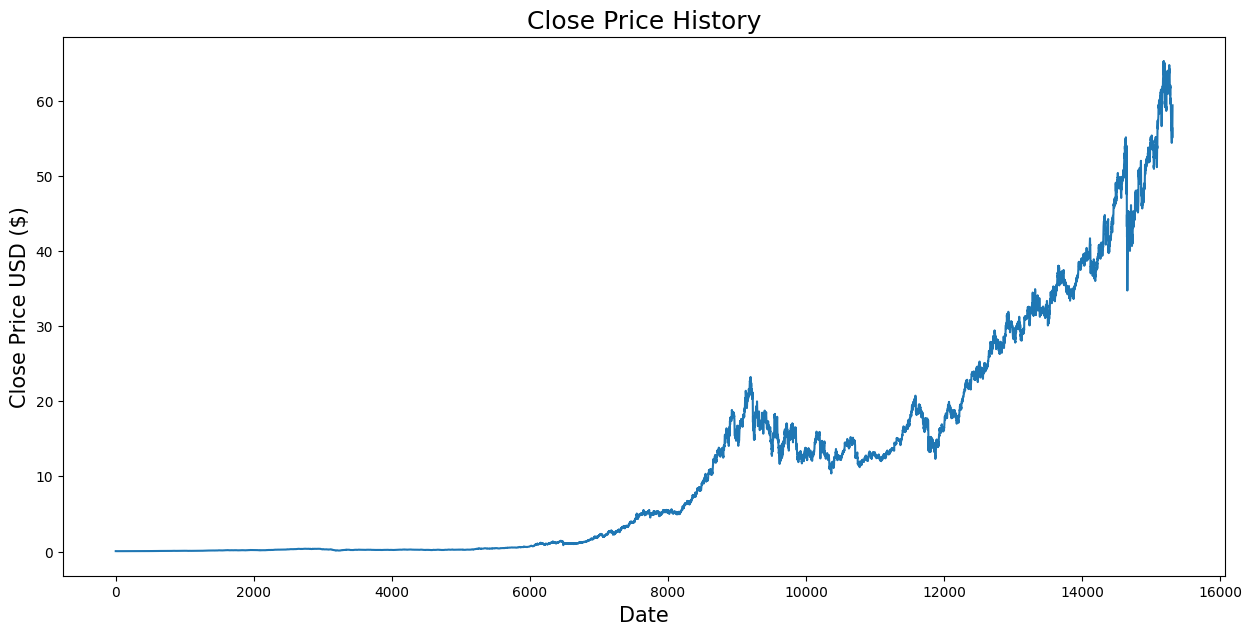

In [ ]:
# Visualizing the closing price history
plt.figure(figsize=(15,7))
plt.title('Close Price History', fontsize=18)
plt.plot(df['Close'])
plt.xlabel('Date', fontsize=15)
plt.ylabel('Close Price USD ($)', fontsize=15)
plt.show()

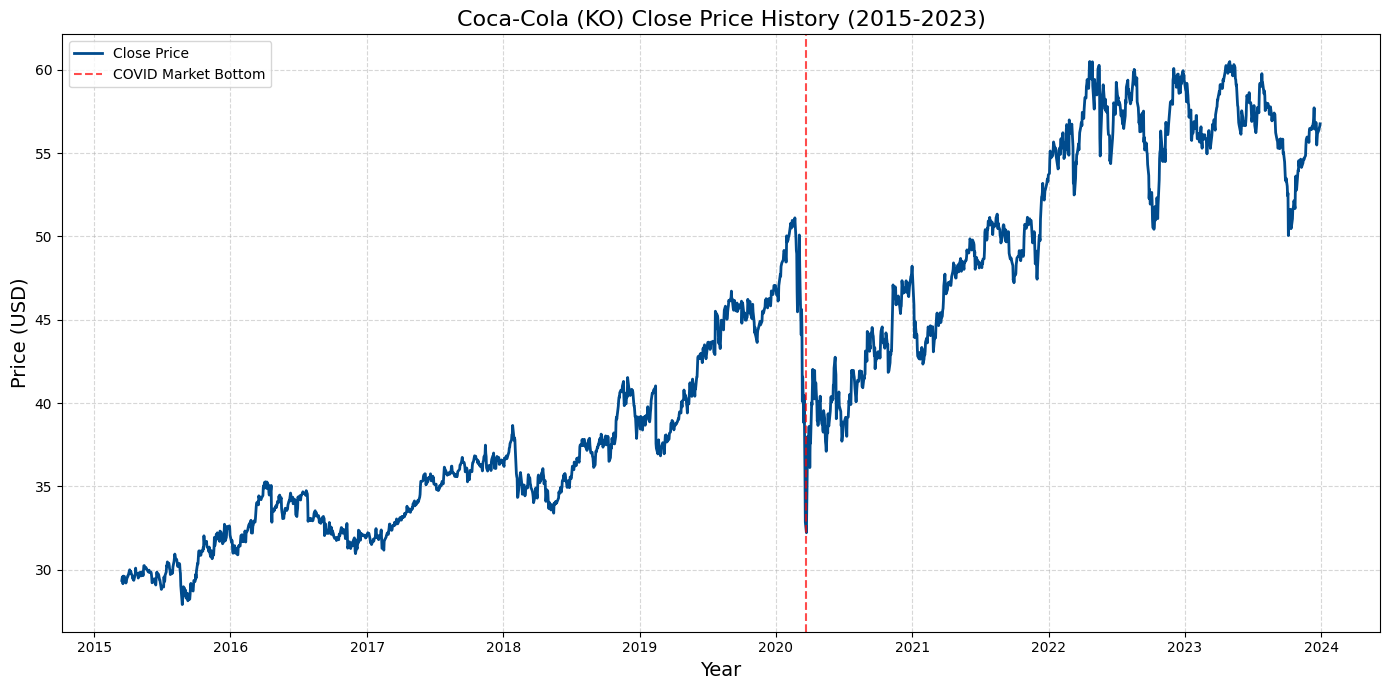

In [ ]:
# Visualizing the closing price history
# Closing Price Over Time
plt.figure(figsize=(14, 7))
plt.plot(data['Date'], data['Close'],
         label='Close Price',
         color='#004b8d',  # Coca-Cola brand blue
         linewidth=2)
plt.title('Coca-Cola (KO) Close Price History (2015-2023)', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Price (USD)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)

# Add important events (example)
plt.axvline(pd.to_datetime('2020-03-23'), color='red', linestyle='--', alpha=0.7,
            label='COVID Market Bottom')
plt.legend()
plt.tight_layout()
plt.show()

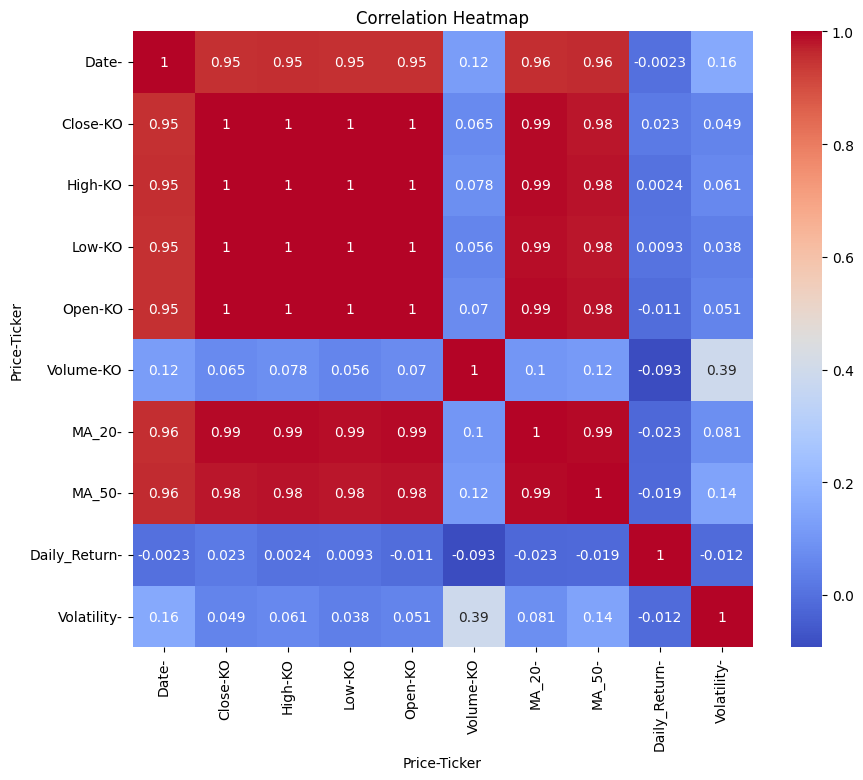

In [ ]:
# Correlation Heatmap of Numeric Features
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

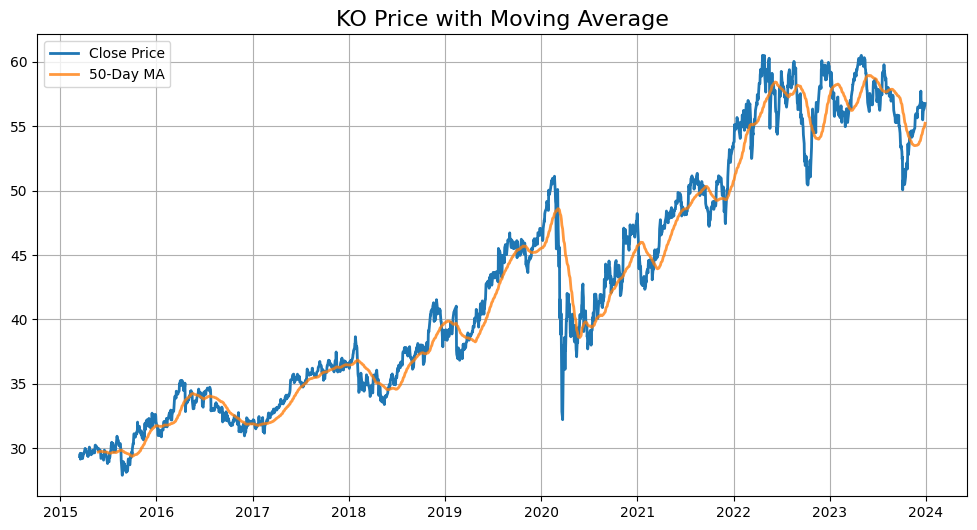

In [ ]:
# With moving average
plt.figure(figsize=(12, 6))
data['MA50'] = data['Close'].rolling(window=50).mean()
plt.plot(data['Date'], data['Close'], label='Close Price', linewidth=2)
plt.plot(data['Date'], data['MA50'], label='50-Day MA', linewidth=2, alpha=0.8)
plt.title(f'{ticker} Price with Moving Average', fontsize=16)
plt.legend()
plt.grid(True)
plt.show()

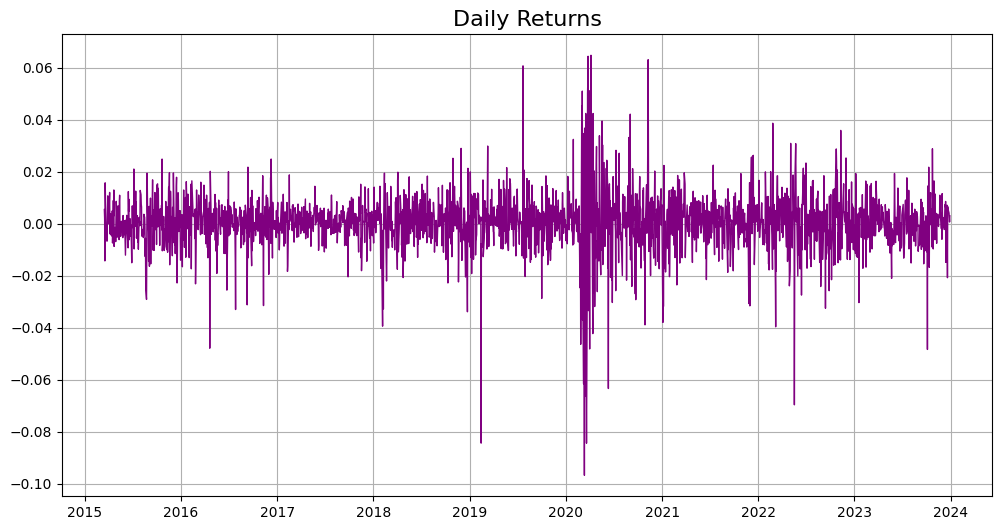

In [ ]:
# Daily returns
data['Daily Return'] = data['Close'].pct_change()
plt.figure(figsize=(12, 6))
plt.plot(data['Date'], data['Daily Return'], color='purple', linewidth=1)
plt.title('Daily Returns', fontsize=16)
plt.grid(True)
plt.show()

Data Splitting

In [ ]:
# Using the 'Close' column for prediction
data = df.filter(['Close'])
dataset = data.values

In [ ]:
# Preparing the data for Random Forest Regressor model
X = data.index.values.reshape(-1, 1)
y = data['Close'].values

In [ ]:
# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Training the Random Forest Regressor Model
rfr_model = RandomForestRegressor(n_estimators=100)
rfr_model.fit(X_train, y_train)

RandomForestRegressor()

In [ ]:
# Predicting and evaluating the Random Forest model
rfr_predictions = rfr_model.predict(X_test)
rfr_rmse = np.sqrt(mean_squared_error(y_test, rfr_predictions))
print('Random Forest Model RMSE:', rfr_rmse)

Random Forest Model RMSE: 21.57134596303121


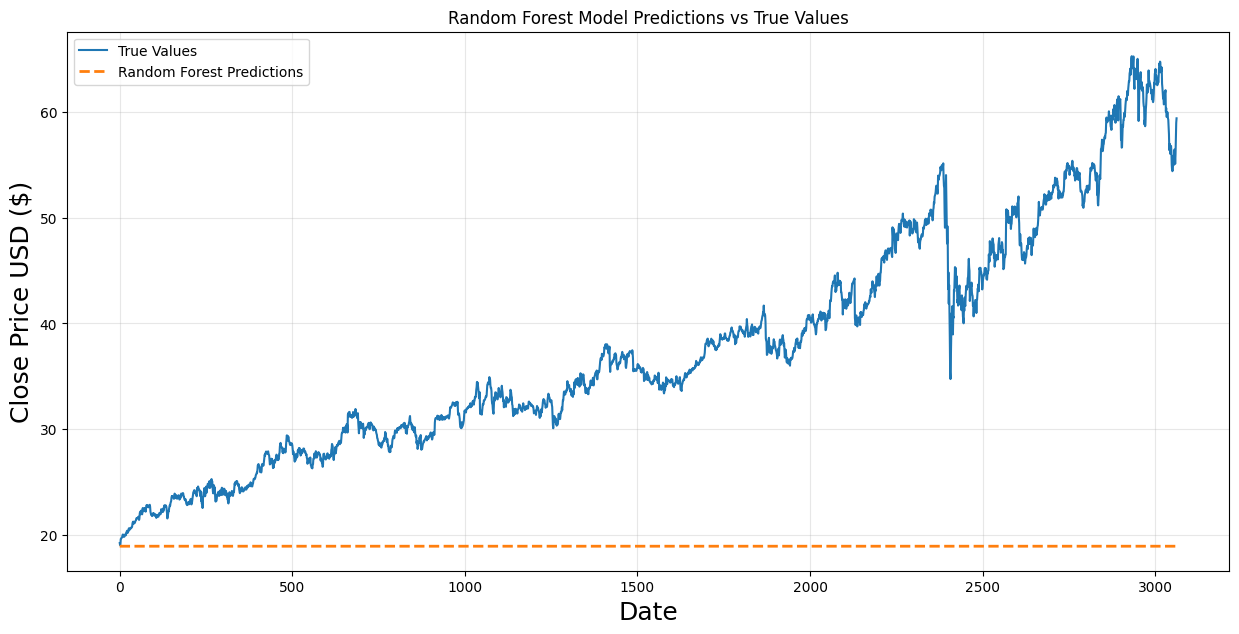

In [ ]:
# Visualizing the Results for Random Forest
plt.figure(figsize=(15,7))
plt.title('Random Forest Model Predictions vs True Values')
plt.plot(y_test, label='True Values')
plt.plot(rfr_predictions, label='Random Forest Predictions', linestyle='--', linewidth=2)
plt.xlabel('Date', fontsize=18)
plt.ylabel('Close Price USD ($)', fontsize=18)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()